# F3 — Prévision de l’inflation (régression sur séries mensuelles)

| N° | Sujet | Type de tâche | Algorithmes compatibles | Point d’attention |
|---|---|---|---|---|
| F3 | Prévision de l’inflation | Régression sur séries mensuelles | 1, 2, 3, 6, 7, 16 | Séries révisées après publication (**biais d’anticipation**). |

**Algorithmes traités (numérotation du TP) :** 1 Régression linéaire · 2 Ridge · 3 Lasso · 6 Forêt aléatoire (régression) · 7 Gradient Boosting (régression) · 16 XGBoost.

**Données :** `Base_de_donne__inflation.xlsx` — taux d’inflation (%), taux de chômage (%) et taux directeur (%), mensuels, de 1954-07 à 2026-10.

**Démarche (et réponse au point d’attention)**
1. Chargement, exploration, traitement *causal* des valeurs manquantes (jamais d’information du futur).
2. Variables construites **uniquement à partir du passé** de la date d’origine *t* ; cible = inflation à *t + h*.
3. Découpage **chronologique** : apprentissage jusqu’en 2009, test de 2010 à 2026 (jamais de mélange aléatoire).
4. Réglage des hyperparamètres par `TimeSeriesSplit` (avec `gap = h`), puis évaluation en **marche avant** (*walk-forward*) avec ré-entraînement annuel.
5. Comparaison à un **modèle naïf** (l’inflation de demain = celle d’aujourd’hui) : c’est le vrai juge de paix.
6. Étude du biais d’anticipation : fuite par validation aléatoire, bruit de révision, limites des données.

**Binôme :** à compléter · **Graine :** 42

In [1]:
!pip -q install scikit-learn xgboost openpyxl

In [2]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

plt.rcParams.update({'figure.dpi':100,'axes.grid':True,'grid.alpha':.3,'font.size':9})
GRAINE = 42
DEBUT_TEST = pd.Period('2010-01', freq='M')   # début de la période de test (tout ce qui précède sert à apprendre)
print('Imports OK')

Imports OK


## 0. Chargement des données

Si le fichier Excel n’est pas déjà dans l’environnement Colab, la cellule suivante ouvre une fenêtre de téléversement : choisissez `Base_de_donne__inflation.xlsx`.

In [3]:
FICHIER = 'Base_de_donne__inflation.xlsx'
if not os.path.exists(FICHIER):
    try:
        from google.colab import files
        print('Téléversez le fichier Excel de la base de données :')
        FICHIER = list(files.upload())[0]
    except ImportError:
        raise FileNotFoundError(f'Placez {FICHIER} dans le dossier courant.')

df = pd.read_excel(FICHIER)
df.columns = ['date', 'infl', 'chom', 'taux']      # infl = inflation (%), chom = chômage (%), taux = taux directeur (%)
df['date'] = pd.PeriodIndex(df['date'], freq='M')
df = df.set_index('date').sort_index()
assert len(df) == (df.index[-1] - df.index[0]).n + 1, 'des mois manquent dans la série'
print('Dimensions :', df.shape, '| de', df.index[0], 'à', df.index[-1])
display(df.head()); display(df.tail())

Téléversez le fichier Excel de la base de données :


Saving Base de donne  inflation (1).xlsx to Base de donne  inflation (1).xlsx
Dimensions : (868, 3) | de 1954-07 à 2026-10


,infl,chom,taux
date,,,
1954-07,0.26,5.8,0.80
1954-08,0.00,6.0,1.22
1954-09,-0.30,6.1,1.07
1954-10,-0.85,5.7,0.85
1954-11,-0.26,5.3,0.83


,infl,chom,taux
date,,,
2026-06,3.46,4.2,3.63
2026-07,3.30,4.1,3.63
2026-08,3.35,4.1,3.63
2026-09,3.72,4.2,3.75
2026-10,NaN,4.1,3.88


## 1. Exploration

Trois choses à regarder : les valeurs manquantes, les régimes (années 70, taux zéro après 2008, choc de 2021-22) et la **persistance** de l’inflation (corrélation avec elle-même).

Valeurs manquantes :
infl    2
chom    1
taux    0
dtype: int64


,infl,chom,taux
date,,,
2025-10,NaN,NaN,4.09
2026-10,NaN,4.1,3.88



Autocorrélation de l’inflation  (décalage 1 mois : 0.991 | 12 mois : 0.734)


,count,mean,std,min,25%,50%,75%,max
infl,866.0,3.57,2.76,-1.96,1.73,2.94,4.37,14.59
chom,867.0,5.79,1.67,3.40,4.40,5.50,6.85,14.80
taux,868.0,4.59,3.52,0.05,1.94,4.24,6.10,19.10


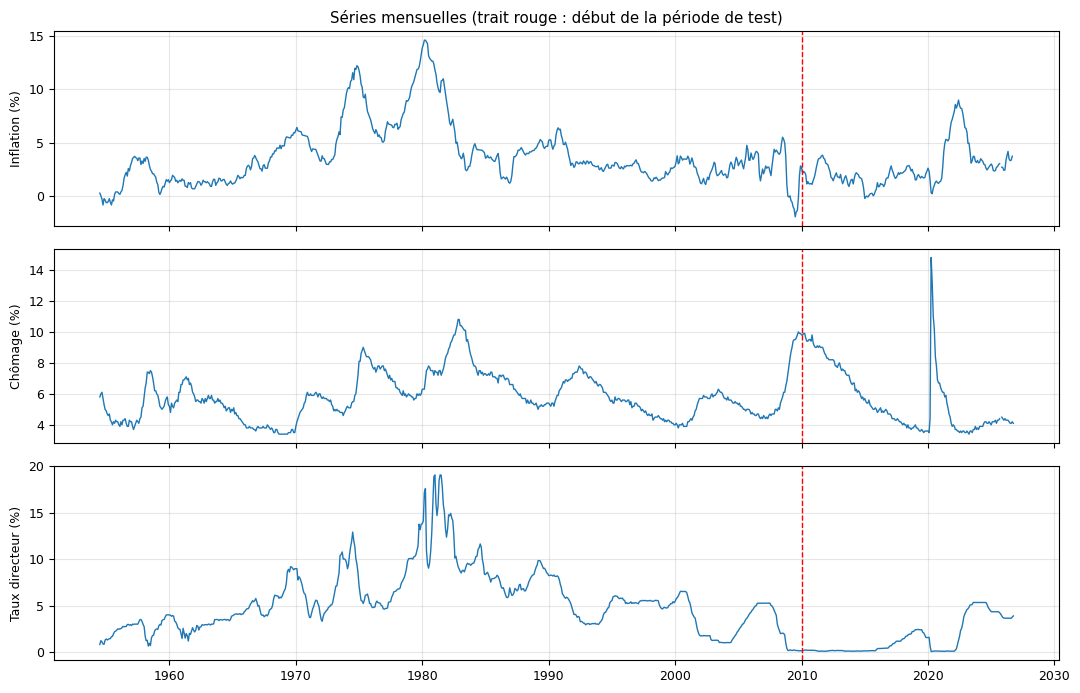

In [4]:
print('Valeurs manquantes :'); print(df.isna().sum()); display(df[df.isna().any(axis=1)])
print('\nAutocorrélation de l’inflation  (décalage 1 mois : %.3f | 12 mois : %.3f)' % (df.infl.autocorr(1), df.infl.autocorr(12)))
display(df.describe().T.round(2))

t = df.index.to_timestamp()
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a, c, nom in zip(ax, ['infl', 'chom', 'taux'], ['Inflation (%)', 'Chômage (%)', 'Taux directeur (%)']):
    a.plot(t, df[c], lw=1); a.set_ylabel(nom)
    a.axvline(DEBUT_TEST.to_timestamp(), color='r', ls='--', lw=1)
ax[0].set_title('Séries mensuelles (trait rouge : début de la période de test)'); plt.tight_layout(); plt.show()

**Lecture.** L’inflation est extrêmement persistante : la valeur d’un mois explique presque entièrement celle du mois suivant. Un modèle de ML doit donc **battre le naïf** (« demain = aujourd’hui »), ce qui est beaucoup plus difficile que de battre la moyenne. Les trous (2025-10 et le dernier mois, non encore publiés) sont traités à l’étape suivante.

## 2. Préparation sans fuite d’information

Règles appliquées (c’est le cœur du point d’attention) :
- **Valeurs manquantes des variables explicatives : report de la dernière valeur connue (`ffill`)**, jamais d’interpolation (une interpolation utiliserait la valeur *suivante*, donc le futur).
- On **coupe** la fin de la série tant que l’inflation du dernier mois n’est pas publiée : l’origine de prévision est la dernière date où l’inflation est connue.
- **Cible** : inflation à *t + h*. On prédit la **variation** `y(t+h) − y(t)` puis on ajoute l’inflation actuelle. Cela évite qu’un modèle à arbres (qui n’extrapole pas) doive deviner un *niveau* ; la section Forêt aléatoire compare les deux choix.
- Toutes les variables d’une ligne *t* ne dépendent que de dates ≤ *t*.

In [5]:
SERIE_INFL = df['infl'].copy()                         # cible : on garde les NaN réels (pas de valeur inventée)
derniere = SERIE_INFL.last_valid_index()
SRC = df.loc[:derniere].ffill()                        # variables : report causal de la dernière valeur connue
SERIE_INFL = SERIE_INFL.loc[:derniere]
print('Dernière origine de prévision (inflation connue) :', derniere)

def variables(src):
    """Variables à la date d'origine t : uniquement du passé."""
    f = pd.DataFrame(index=src.index)
    f['infl'] = src.infl
    for k in (1, 2, 3, 6, 12):
        f[f'infl_l{k}'] = src.infl.shift(k)            # inflation retardée
    f['chom'] = src.chom
    f['chom_l3'] = src.chom.shift(3)
    f['d_chom_12'] = src.chom.diff(12)                 # variation annuelle du chômage
    f['taux'] = src.taux
    f['d_taux_3'] = src.taux.diff(3)                   # resserrement / assouplissement récent
    f['d_taux_12'] = src.taux.diff(12)
    return f

FEATS = variables(SRC)
COLS = list(FEATS.columns)

def jeu(h=1, cible='variation'):
    """Table supervisée : variables à t -> cible à t+h ('variation' ou 'niveau')."""
    d = FEATS.copy()
    d['base'] = FEATS['infl']                          # inflation connue à l'origine
    d['y_niv'] = SERIE_INFL.shift(-h)                  # inflation réellement observée à t+h
    d['y'] = d['y_niv'] - d['base'] if cible == 'variation' else d['y_niv']
    return d.dropna(subset=COLS + ['y'])

d1 = jeu(1)
print('Variables :', COLS)
print('Observations (h=1) :', len(d1), '| apprentissage :', int((d1.index + 1 <= DEBUT_TEST).sum()), '| test :', int((d1.index >= DEBUT_TEST).sum()))
display(d1.tail(3).round(2))

Dernière origine de prévision (inflation connue) : 2026-09
Variables : ['infl', 'infl_l1', 'infl_l2', 'infl_l3', 'infl_l6', 'infl_l12', 'chom', 'chom_l3', 'd_chom_12', 'taux', 'd_taux_3', 'd_taux_12']
Observations (h=1) : 853 | apprentissage : 654 | test : 199


,infl,infl_l1,infl_l2,infl_l3,infl_l6,infl_l12,chom,chom_l3,d_chom_12,taux,d_taux_3,d_taux_12,base,y_niv,y
date,,,,,,,,,,,,,,,
2026-06,3.46,4.17,3.78,3.29,2.65,2.68,4.2,4.3,0.1,3.63,-0.01,-0.7,3.46,3.30,-0.16
2026-07,3.30,3.46,4.17,3.78,2.39,2.74,4.1,4.3,-0.2,3.63,-0.01,-0.7,3.30,3.35,0.05
2026-08,3.35,3.30,3.46,4.17,2.43,2.94,4.1,4.3,-0.2,3.63,0.00,-0.7,3.35,3.72,0.37


## 3. Protocole d’évaluation (commun à tous les algorithmes)

- **Apprentissage initial :** observations dont la cible est connue avant 2010-01 (`t + h ≤ 2010-01`), donc **aucune cible du futur** dans l’apprentissage (purge de *h* mois).
- **Réglage :** `GridSearchCV` + `TimeSeriesSplit(5, gap=h)` sur cet apprentissage uniquement (le test n’est jamais utilisé pour choisir).
- **Évaluation :** marche avant. Chaque année *A* de 2010 à 2026, le modèle est ré-entraîné avec toutes les cibles connues au 1ᵉʳ mois de *A*, puis prédit les 12 mois de *A*.
- **Métriques :** MAE et RMSE en points d’inflation, et **ratio MAE / MAE du naïf** (< 1 : le modèle bat le naïf).

In [6]:
def marche_avance(fabrique, h=1, cible='variation', colonnes=None, bruit=0.):
    """Prévisions de 2010 à la fin, avec ré-entraînement annuel ; bruit = écart-type de révision simulée sur le chômage."""
    colonnes = colonnes or COLS
    d = jeu(h, cible)
    idx_test = d.index[d.index >= DEBUT_TEST]
    pred = pd.Series(index=idx_test, dtype=float)
    rng = np.random.default_rng(GRAINE)
    for annee in sorted(set(idx_test.year)):
        bloc = idx_test[idx_test.year == annee]
        ent = d[(d.index + h) <= bloc[0]]                    # seulement des cibles déjà connues à l'origine
        modele = fabrique().fit(ent[colonnes], ent['y'])
        Xb = d.loc[bloc, colonnes].copy()
        if bruit > 0:                                        # valeur "préliminaire" du chômage, non encore révisée
            e = rng.normal(0, bruit, len(Xb))
            for c in ('chom', 'd_chom_12'):
                if c in Xb: Xb[c] = Xb[c] + e
        pred.loc[bloc] = modele.predict(Xb)
    s = d.loc[idx_test, ['base', 'y_niv']].copy()
    s['pred'] = pred + (s['base'] if cible == 'variation' else 0.)
    return s

def metriques(s):
    e = s['pred'] - s['y_niv']
    return {'MAE': e.abs().mean(), 'RMSE': float(np.sqrt((e ** 2).mean()))}

def naif(h=1):
    """Référence : l'inflation reste égale à sa dernière valeur connue."""
    d = jeu(h); s = d.loc[d.index >= DEBUT_TEST, ['base', 'y_niv']].copy(); s['pred'] = s['base']; return s

def mae_naif_cv(h=1):
    d = jeu(h); ent0 = d[(d.index + h) <= DEBUT_TEST]
    return float(np.mean([ent0['y'].iloc[v].abs().mean() for _, v in TimeSeriesSplit(5, gap=h).split(ent0)]))

RESULTATS = {}
def evaluer_modele(nom, pipe, grille, h=1, cible='variation'):
    """Réglage chronologique + évaluation en marche avant ; résultat mis en cache."""
    cle = (nom, h, cible)
    if cle in RESULTATS: return RESULTATS[cle]
    d = jeu(h, cible); ent0 = d[(d.index + h) <= DEBUT_TEST]
    gs = GridSearchCV(pipe, grille, cv=TimeSeriesSplit(5, gap=h), scoring='neg_mean_absolute_error', n_jobs=-1)
    gs.fit(ent0[COLS], ent0['y'])
    best = gs.best_params_
    fabrique = lambda: clone(pipe).set_params(**best)
    s = marche_avance(fabrique, h, cible)
    RESULTATS[cle] = dict(sortie=s, params=best, gs=gs, fabrique=fabrique, pipe=pipe, grille=grille, ent0=ent0, **metriques(s))
    return RESULTATS[cle]

def resume(nom, h=1, cible='variation'):
    r = RESULTATS[(nom, h, cible)]; n = metriques(naif(h))
    print(f"{nom} (h={h}, cible={cible}) — hyperparamètres retenus : {r['params']}")
    print(f"  MAE {r['MAE']:.3f} | RMSE {r['RMSE']:.3f}   ||   naïf : MAE {n['MAE']:.3f} | RMSE {n['RMSE']:.3f}   ||   ratio MAE/naïf = {r['MAE']/n['MAE']:.3f}")

def tracer(noms, h=1, depuis='2015-01'):
    n = naif(h).loc[pd.Period(depuis, 'M'):]
    plt.figure(figsize=(11, 3.8)); plt.plot(n.index.to_timestamp(), n['y_niv'], 'k', lw=2, label='Réel')
    plt.plot(n.index.to_timestamp(), n['pred'], 'grey', ls=':', label='Naïf')
    for nom in noms:
        s = RESULTATS[(nom, h, 'variation')]['sortie'].loc[pd.Period(depuis, 'M'):]; plt.plot(s.index.to_timestamp(), s['pred'], lw=1.3, label=nom)
    plt.legend(); plt.title(f'Inflation à t+{h} : réel vs prévisions en marche avant'); plt.ylabel('%'); plt.show()

def courbe_cv(nom, param, h=1, log=False):
    """Variation d'un hyperparamètre, jugée par validation chronologique sur l'apprentissage (pas sur le test)."""
    r = RESULTATS[(nom, h, 'variation')]; c = pd.DataFrame(r['gs'].cv_results_)
    c['MAE_cv'] = -c['mean_test_score']; c['v'] = c['param_' + param].astype(float)
    g = c.groupby('v')['MAE_cv'].min()
    plt.figure(figsize=(6, 3.2)); plt.plot(g.index, g.values, 'o-', label='MAE validation chronologique')
    plt.axhline(mae_naif_cv(h), color='grey', ls=':', label='MAE du naïf (mêmes plis)')
    if log: plt.xscale('log')
    plt.xlabel(param); plt.ylabel('MAE (points)'); plt.legend(); plt.title(f'{nom} — effet de {param}'); plt.show()
    return g.round(4)

print('Référence naïve (h=1) :', {k: round(v, 3) for k, v in metriques(naif(1)).items()})

Référence naïve (h=1) : {'MAE': np.float64(0.277), 'RMSE': 0.367}


## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables explicatives et la cible peut être insuffisante.

**Présentation.** Elle ajuste `y = β₀ + Σ βⱼ xⱼ` par moindres carrés. Ici, `y` est la variation d’inflation à *h* mois et les `xⱼ` sont l’inflation retardée, le chômage et le taux directeur. Elle est rapide, interprétable, et sert de référence « simple mais sérieuse ».

**Deux cas d’usage.** (1) Estimer l’effet moyen d’une variation du chômage sur l’inflation (courbe de Phillips). (2) Prévision rapide de court terme d’un indicateur macro à partir de ses retards.

**Pourquoi c’est parfois insuffisant ici.** La relation chômage–inflation change selon les régimes (années 70, ère des taux zéro, 2021-22) et peut être non linéaire (effets de seuil) ; les variables sont très corrélées entre elles (retards d’inflation) ce qui rend les coefficients instables ; un seul jeu de coefficients ne peut pas décrire des périodes structurellement différentes.

Linéaire (h=1, cible=variation) — hyperparamètres retenus : {}
  MAE 0.272 | RMSE 0.355   ||   naïf : MAE 0.277 | RMSE 0.367   ||   ratio MAE/naïf = 0.981


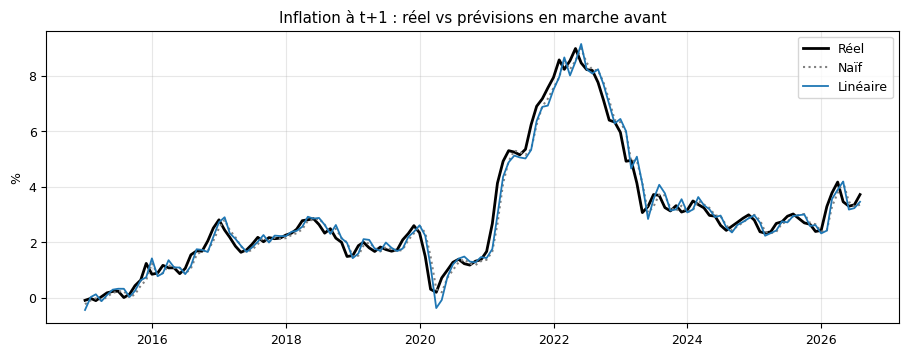


Inflation seule  (AR) : MAE 0.257 | toutes variables : MAE 0.272 | naïf : MAE 0.277


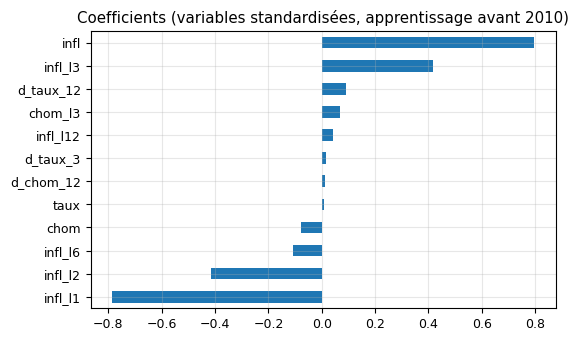

In [7]:
pipe_lin = make_pipeline(StandardScaler(), LinearRegression())
r = evaluer_modele('Linéaire', pipe_lin, {})
resume('Linéaire')
tracer(['Linéaire'])

# Variation « d'hyperparamètre » : quelles variables ? inflation seule vs toutes les variables
col_infl = [c for c in COLS if c.startswith('infl')]
s_infl = marche_avance(r['fabrique'], 1, colonnes=col_infl)
print('\nInflation seule  (AR) : MAE %.3f' % metriques(s_infl)['MAE'], '| toutes variables : MAE %.3f' % r['MAE'], '| naïf : MAE %.3f' % metriques(naif(1))['MAE'])

m = clone(pipe_lin).fit(r['ent0'][COLS], r['ent0']['y'])
coef = pd.Series(m[-1].coef_, index=COLS).sort_values()
coef.plot.barh(figsize=(6, 3.6), title='Coefficients (variables standardisées, apprentissage avant 2010)'); plt.show()

**Analyse de la sortie (à compléter après exécution).** Comparez la MAE au naïf : si le ratio est proche de 1, le linéaire n’apporte presque rien sur l’inflation seule. Regardez si l’ajout du chômage et du taux directeur améliore réellement la MAE par rapport au modèle « inflation seule ». Notez les coefficients de signes opposés sur des retards voisins : symptôme de colinéarité.

## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**Présentation.** Même modèle que la régression linéaire, mais on minimise `Σ(erreur)² + α Σ βⱼ²`. La pénalité L2 **rétrécit** les coefficients et stabilise les variables corrélées.

**Deux cas d’usage.** (1) Beaucoup de retards très corrélés (cas présent). (2) Peu d’observations par rapport au nombre de variables.

**Réponse à la question.** Quand α devient très grand, tous les coefficients tendent vers 0 : le modèle prédit alors une variation constante (≈ 0), c’est-à-dire **le modèle naïf**. Ridge interpole donc entre la régression linéaire (α = 0) et le naïf (α → ∞) ; la courbe ci-dessous le montre.

Ridge (h=1, cible=variation) — hyperparamètres retenus : {'ridge__alpha': np.float64(316.22776601683796)}
  MAE 0.284 | RMSE 0.377   ||   naïf : MAE 0.277 | RMSE 0.367   ||   ratio MAE/naïf = 1.024


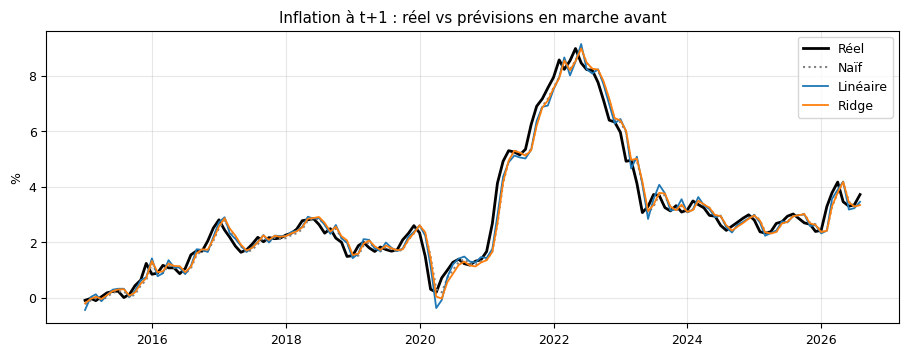

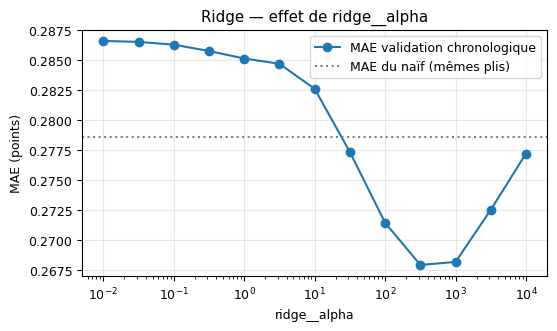

,MAE_cv
v,
0.010000,0.2866
0.031623,0.2865
0.100000,0.2863
0.316228,0.2858
1.000000,0.2851
3.162278,0.2847
10.000000,0.2826
31.622777,0.2773
100.000000,0.2714


In [8]:
pipe_ridge = make_pipeline(StandardScaler(), Ridge())
r = evaluer_modele('Ridge', pipe_ridge, {'ridge__alpha': np.logspace(-2, 4, 13)})
resume('Ridge')
tracer(['Linéaire', 'Ridge'])
courbe_cv('Ridge', 'ridge__alpha', log=True)

**Analyse de la sortie (à compléter).** Repérez la valeur de α retenue et si la courbe remonte vers la MAE du naïf pour α très grand (attendu). Si le gain de Ridge sur la régression linéaire est faible, la colinéarité n’était pas le facteur limitant.

## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**Présentation.** On minimise `Σ(erreur)² + α Σ |βⱼ|`. La pénalité L1 a un « coin » en zéro : à partir d’un certain α, des coefficients sont **exactement nuls**, donc des variables sont éliminées.

**Deux cas d’usage.** (1) Identifier quels retards et quels indicateurs macro comptent vraiment. (2) Construire un modèle parcimonieux, plus facile à expliquer à un comité.

**Réponse à la question.** Plus α augmente, plus de coefficients passent à 0, dans l’ordre inverse de leur utilité prédictive ; le chemin de régularisation ci-dessous montre l’ordre de disparition des variables.

Lasso (h=1, cible=variation) — hyperparamètres retenus : {'lasso__alpha': np.float64(0.021544346900318822)}
  MAE 0.283 | RMSE 0.378   ||   naïf : MAE 0.277 | RMSE 0.367   ||   ratio MAE/naïf = 1.020


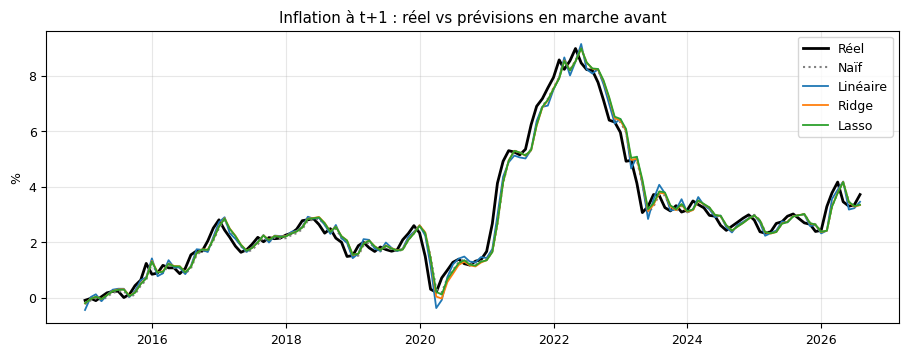

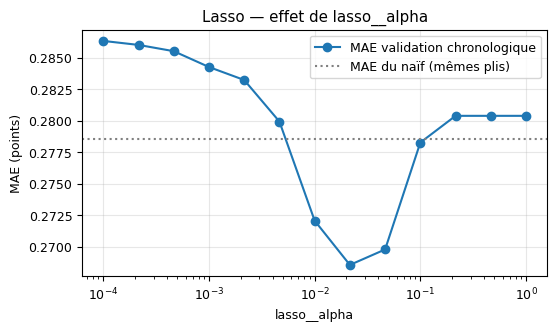


Variables conservées : ['infl_l2', 'd_taux_3', 'd_taux_12']
Variables éliminées : ['infl', 'infl_l1', 'infl_l3', 'infl_l6', 'infl_l12', 'chom', 'chom_l3', 'd_chom_12', 'taux']


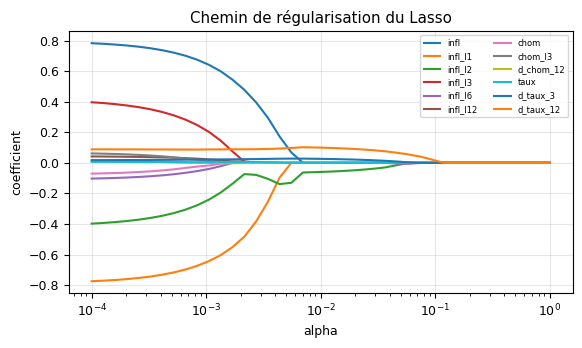

In [9]:
pipe_lasso = make_pipeline(StandardScaler(), Lasso(max_iter=50000))
r = evaluer_modele('Lasso', pipe_lasso, {'lasso__alpha': np.logspace(-4, 0, 13)})
resume('Lasso')
tracer(['Linéaire', 'Ridge', 'Lasso'])
courbe_cv('Lasso', 'lasso__alpha', log=True)

# Variables retenues + chemin de régularisation
m = clone(pipe_lasso).set_params(**r['params']).fit(r['ent0'][COLS], r['ent0']['y'])
coef = pd.Series(m[-1].coef_, index=COLS)
print('\nVariables conservées :', list(coef[coef != 0].index)); print('Variables éliminées :', list(coef[coef == 0].index))
alphas = np.logspace(-4, 0, 40); Xs = StandardScaler().fit_transform(r['ent0'][COLS])
chemin = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs, r['ent0']['y']).coef_ for a in alphas])
plt.figure(figsize=(6.5, 3.4)); plt.plot(alphas, chemin); plt.xscale('log'); plt.xlabel('alpha'); plt.ylabel('coefficient')
plt.title('Chemin de régularisation du Lasso'); plt.legend(COLS, fontsize=6, ncol=2); plt.show()

**Analyse de la sortie (à compléter).** Quelles variables survivent à l’α retenu ? Les retards d’inflation et la variation du taux directeur ressortent-ils avant le chômage ? Comparez la MAE de Lasso à celle de Ridge : à performance égale, Lasso est préférable s’il garde moins de variables.

## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**Présentation.** On entraîne de nombreux arbres, chacun sur un échantillon **bootstrap** (tirage avec remise) des observations et un sous-ensemble aléatoire de variables à chaque coupure. La prévision est la **moyenne** des arbres.

**Deux cas d’usage.** (1) Relations non linéaires et interactions (effet du chômage différent selon le niveau des taux). (2) Données bruitées où un arbre seul sur-apprend.

**Réponse à la question.** Un arbre profond a une variance élevée ; en moyennant des arbres entraînés sur des échantillons différents, les erreurs individuelles se compensent en partie, ce qui réduit la variance sans trop augmenter le biais.

**Point d’attention propre aux arbres.** Une feuille prédit la moyenne de cibles **déjà vues** : un arbre ne peut pas prédire une valeur hors de la plage d’apprentissage. Prédire le *niveau* de l’inflation est donc risqué ; prédire la *variation* (cible choisie ici) limite le problème. La cellule compare les deux.

Forêt (h=1, cible=variation) — hyperparamètres retenus : {'max_depth': 4, 'min_samples_leaf': 8}
  MAE 0.288 | RMSE 0.391   ||   naïf : MAE 0.277 | RMSE 0.367   ||   ratio MAE/naïf = 1.039


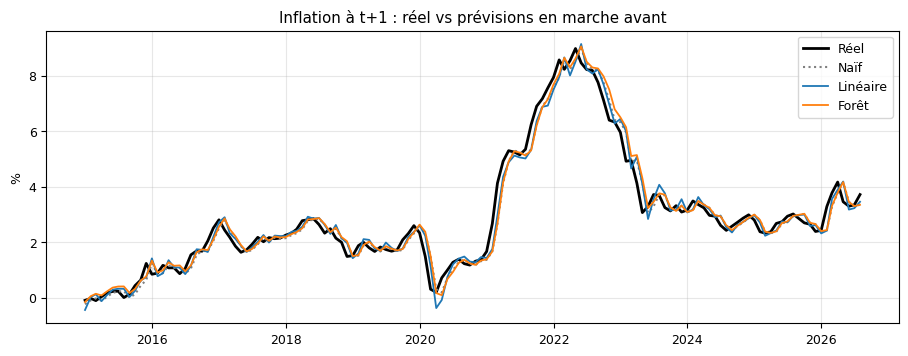

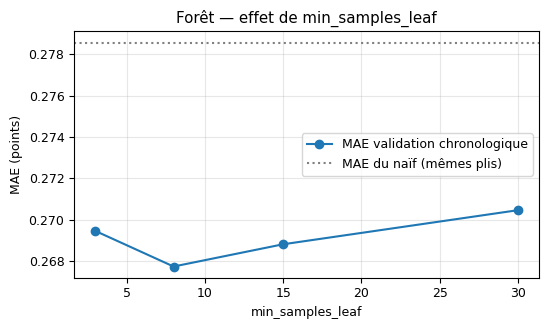

Forêt (h=1, cible=niveau) — hyperparamètres retenus : {'max_depth': None, 'min_samples_leaf': 3}
  MAE 0.300 | RMSE 0.405   ||   naïf : MAE 0.277 | RMSE 0.367   ||   ratio MAE/naïf = 1.082
Plage de l’inflation à l’apprentissage : -2.0 à 14.6 | maximum observé en test : 9.0


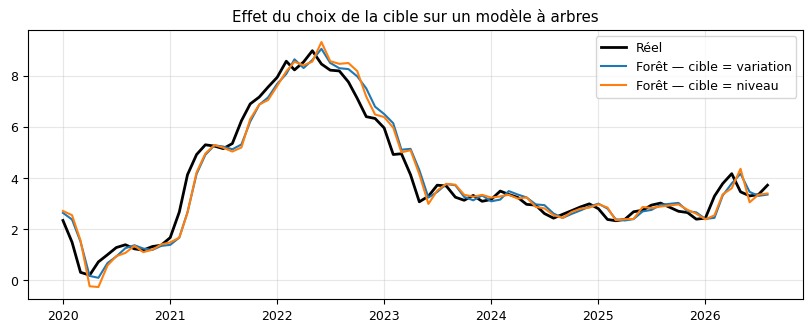

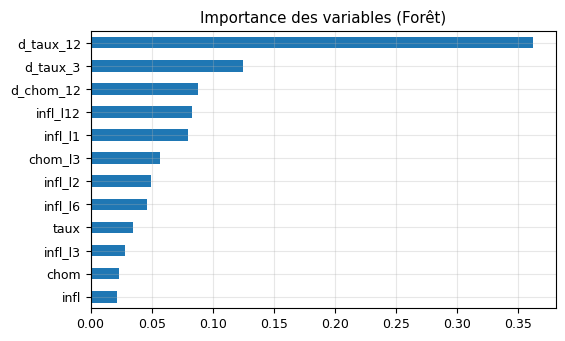

In [11]:
pipe_rf = RandomForestRegressor(n_estimators=150, random_state=GRAINE, n_jobs=1)
grille_rf = {'min_samples_leaf': [3, 8, 15, 30], 'max_depth': [4, 8, None]}
r = evaluer_modele('Forêt', pipe_rf, grille_rf)
resume('Forêt')
tracer(['Linéaire', 'Forêt'])
courbe_cv('Forêt', 'min_samples_leaf')

# Cible en NIVEAU au lieu de VARIATION : les arbres n'extrapolent pas
r_niv = evaluer_modele('Forêt', pipe_rf, grille_rf, cible='niveau')
resume('Forêt', cible='niveau')
d = jeu(1); print('Plage de l’inflation à l’apprentissage : %.1f à %.1f | maximum observé en test : %.1f' % (d.loc[d.index < DEBUT_TEST, 'y_niv'].min(), d.loc[d.index < DEBUT_TEST, 'y_niv'].max(), d.loc[d.index >= DEBUT_TEST, 'y_niv'].max()))
s = r_niv['sortie'].loc[pd.Period('2020-01', 'M'):]; sv = r['sortie'].loc[pd.Period('2020-01', 'M'):]
plt.figure(figsize=(10, 3.5)); plt.plot(s.index.to_timestamp(), s['y_niv'], 'k', lw=2, label='Réel')
plt.plot(sv.index.to_timestamp(), sv['pred'], label='Forêt — cible = variation'); plt.plot(s.index.to_timestamp(), s['pred'], label='Forêt — cible = niveau')
plt.legend(); plt.title('Effet du choix de la cible sur un modèle à arbres'); plt.show()

# Importance des variables (apprentissage avant 2010)
m = r['fabrique']().fit(r['ent0'][COLS], r['ent0']['y'])
pd.Series(m.feature_importances_, index=COLS).sort_values().plot.barh(figsize=(6, 3.6), title='Importance des variables (Forêt)'); plt.show()

**Analyse de la sortie (à compléter).** Comparez les deux cibles : la forêt en *niveau* est-elle nettement moins bonne, surtout à partir de 2021 ? Quelle `min_samples_leaf` est retenue (feuilles larges = modèle plus lissé) ? Quelles variables dominent l’importance ?

## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**Présentation.** On part d’une prévision simple, puis chaque nouvel arbre (petit) apprend les **résidus** (erreurs restantes) du modèle courant ; la prévision finale est la somme pondérée par le `learning_rate`.

**Deux cas d’usage.** (1) Données tabulaires avec interactions complexes. (2) Séries macro où un petit gain de précision compte.

**Réponse à la question.** Chaque arbre dépend des erreurs de ceux qui précèdent : on ne peut donc pas les entraîner indépendamment, contrairement à la forêt. Cette correction progressive réduit le biais, mais un nombre d’arbres trop élevé ou un `learning_rate` trop fort provoque du sur-apprentissage.

Gradient Boosting (h=1, cible=variation) — hyperparamètres retenus : {'learning_rate': 0.03, 'max_iter': 100, 'max_leaf_nodes': 4}
  MAE 0.283 | RMSE 0.386   ||   naïf : MAE 0.277 | RMSE 0.367   ||   ratio MAE/naïf = 1.022


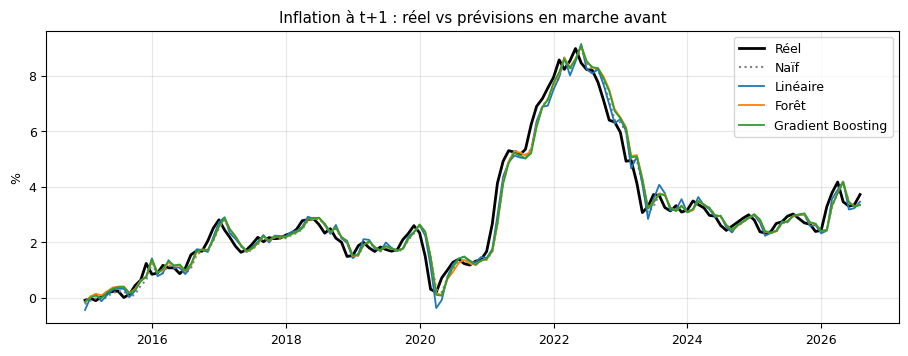

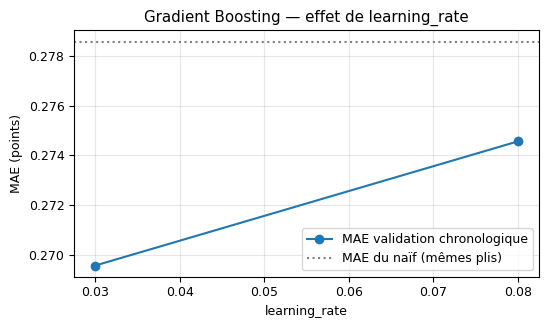

,MAE_cv
v,
0.03,0.2696
0.08,0.2746


In [12]:
pipe_gb = HistGradientBoostingRegressor(random_state=GRAINE)
r = evaluer_modele('Gradient Boosting', pipe_gb, {'max_iter': [100, 250], 'max_leaf_nodes': [4, 8], 'learning_rate': [.03, .08]})
resume('Gradient Boosting')
tracer(['Linéaire', 'Forêt', 'Gradient Boosting'])
courbe_cv('Gradient Boosting', 'learning_rate')

**Analyse de la sortie (à compléter).** Le boosting fait-il mieux que la forêt ? Un `learning_rate` faible avec plus d’itérations est-il retenu (réglage prudent) ? Rappelez-vous que sur des séries macro courtes (≈ 650 observations d’apprentissage) les modèles très flexibles sur-apprennent facilement.

## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**Présentation.** Boosting de gradient avec une fonction objectif **régularisée** (pénalité L2 `reg_lambda` sur les valeurs des feuilles, coût par feuille) et des optimisations d’implémentation.

**Deux cas d’usage.** (1) Compétitions et applications tabulaires. (2) Prévision avec nombreuses variables explicatives de qualité inégale.

**Réponse à la question.** `learning_rate` contrôle la contribution de chaque arbre (petit = apprentissage lent, plus robuste) ; `reg_lambda` rétrécit les valeurs des feuilles et limite le sur-apprentissage. Les deux se compensent avec `n_estimators`.

XGBoost (h=1, cible=variation) — hyperparamètres retenus : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 150, 'reg_lambda': 10}
  MAE 0.286 | RMSE 0.386   ||   naïf : MAE 0.277 | RMSE 0.367   ||   ratio MAE/naïf = 1.032


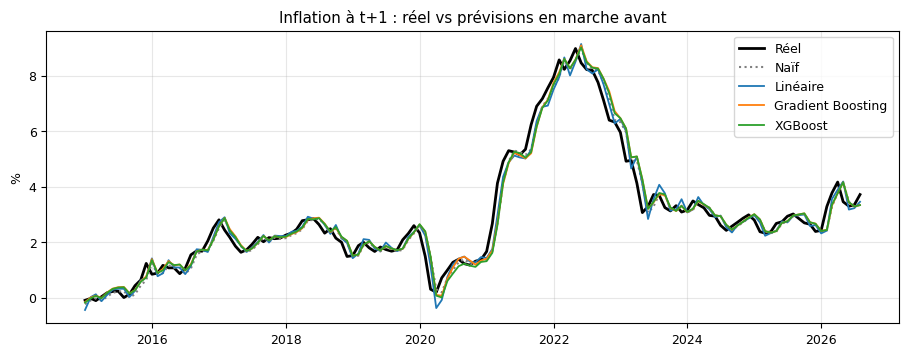

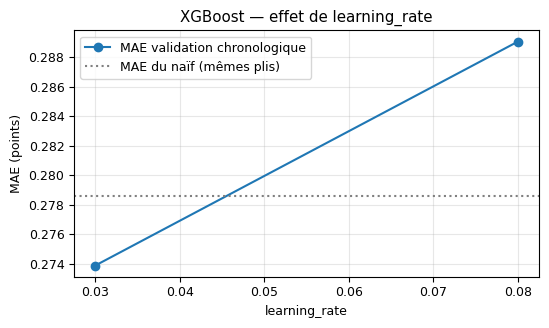

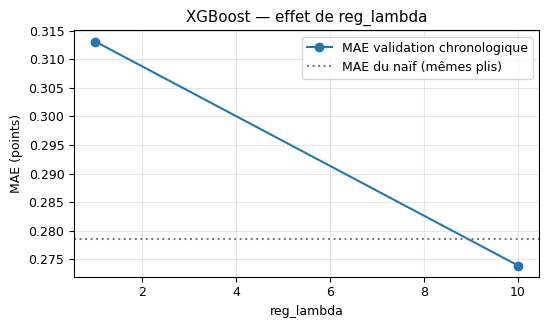

,MAE_cv
v,
1.0,0.3131
10.0,0.2739


In [13]:
pipe_xgb = XGBRegressor(random_state=GRAINE, n_jobs=1, objective='reg:squarederror')
r = evaluer_modele('XGBoost', pipe_xgb, {'n_estimators': [150, 300], 'max_depth': [2, 3], 'learning_rate': [.03, .08], 'reg_lambda': [1, 10]})
resume('XGBoost')
tracer(['Linéaire', 'Gradient Boosting', 'XGBoost'])
courbe_cv('XGBoost', 'learning_rate'); courbe_cv('XGBoost', 'reg_lambda')

**Analyse de la sortie (à compléter).** XGBoost améliore-t-il Gradient Boosting ? Une régularisation plus forte (`reg_lambda` élevé) est-elle retenue ? Si aucun modèle d’arbres ne bat nettement le linéaire, c’est plausible sur ce problème : peu de données et un signal essentiellement linéaire (persistance).

## 4. Comparaison finale (horizon 1 mois)

,MAE,RMSE,MAE / naïf
Linéaire,0.272,0.355,0.981
Naïf,0.277,0.367,1.000
Lasso,0.283,0.378,1.020
Gradient Boosting,0.283,0.386,1.022
Ridge,0.284,0.377,1.024
XGBoost,0.286,0.386,1.032
Forêt,0.288,0.391,1.039


Ratio MAE / naïf par sous-période (< 1 : le modèle bat le naïf)


,2010-2019,2020-2023 (choc),2024-fin
Linéaire,0.94,1.05,0.93
Ridge,0.99,1.07,1.01
Lasso,0.99,1.06,1.02
Forêt,1.02,1.09,0.98
Gradient Boosting,1.00,1.08,0.97
XGBoost,1.00,1.10,0.97


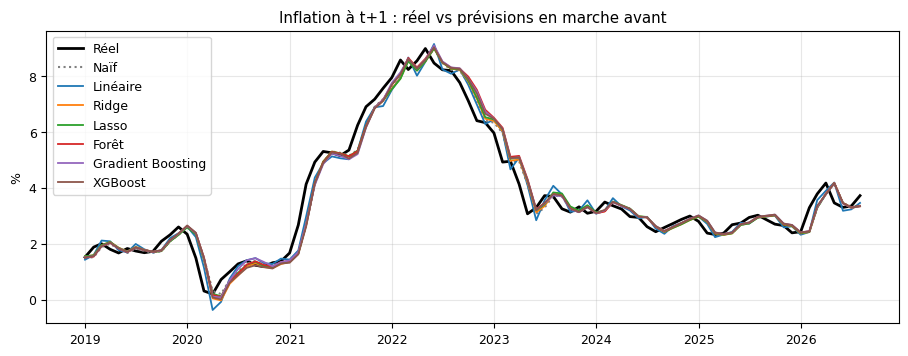

In [14]:
NOMS = ['Linéaire', 'Ridge', 'Lasso', 'Forêt', 'Gradient Boosting', 'XGBoost']
n = metriques(naif(1))
tab = pd.DataFrame({nom: {'MAE': RESULTATS[(nom, 1, 'variation')]['MAE'], 'RMSE': RESULTATS[(nom, 1, 'variation')]['RMSE']} for nom in NOMS}).T
tab.loc['Naïf'] = [n['MAE'], n['RMSE']]
tab['MAE / naïf'] = tab['MAE'] / n['MAE']
display(tab.sort_values('MAE').round(3))

# Erreur par sous-période (rapport au naïf) : où les modèles gagnent ou perdent
periodes = {'2010-2019': ('2010-01', '2019-12'), '2020-2023 (choc)': ('2020-01', '2023-12'), '2024-fin': ('2024-01', '2030-12')}
sp = {}
for nom in NOMS:
    s = RESULTATS[(nom, 1, 'variation')]['sortie']; sn = naif(1); ligne = {}
    for p, (a, b) in periodes.items():
        sl = slice(pd.Period(a, 'M'), pd.Period(b, 'M'))
        ligne[p] = (s.loc[sl, 'pred'] - s.loc[sl, 'y_niv']).abs().mean() / (sn.loc[sl, 'pred'] - sn.loc[sl, 'y_niv']).abs().mean()
    sp[nom] = ligne
print('Ratio MAE / naïf par sous-période (< 1 : le modèle bat le naïf)'); display(pd.DataFrame(sp).T.round(2))
tracer(NOMS, depuis='2019-01')

## 5. Autres horizons (3 et 12 mois)

Plus l’horizon est lointain, plus le naïf se dégrade, et plus un modèle de ML a une chance de l’améliorer.

In [21]:
grilles = {
    'Linéaire': (pipe_lin, {}),
    'Ridge': (pipe_ridge, {'ridge__alpha': np.logspace(-2, 4, 13)}),
    'Lasso': (pipe_lasso, {'lasso__alpha': np.logspace(-4, 0, 13)}),
    'Forêt': (pipe_rf, grille_rf),
    'Gradient Boosting': (pipe_gb, {'max_iter': [100, 250], 'max_leaf_nodes': [4, 8], 'learning_rate': [.03, .08]}),
    'XGBoost': (pipe_xgb, {'n_estimators': [150, 300], 'max_depth': [2, 3], 'learning_rate': [.03, .08], 'reg_lambda': [1, 10]}),
}
lignes = {}
for h in (1, 3, 12):
    nh = metriques(naif(h)); l = {'Naïf (MAE)': nh['MAE']}
    for nom in NOMS:
        r = evaluer_modele(nom, *grilles[nom], h=h); l[nom] = r['MAE'] / nh['MAE']
    lignes[f'h = {h} mois'] = l
print('MAE du naïf, puis ratio MAE / naïf pour chaque modèle (< 1 : bat le naïf)')
display(pd.DataFrame(lignes).T.round(3))

MAE du naïf, puis ratio MAE / naïf pour chaque modèle (< 1 : bat le naïf)


,Naïf (MAE),Linéaire,Ridge,Lasso,Forêt,Gradient Boosting,XGBoost
h = 1 mois,0.277,0.981,1.024,1.020,1.039,1.022,1.032
h = 3 mois,0.607,1.141,1.048,1.026,1.170,1.123,1.169
h = 12 mois,1.473,1.150,1.018,1.011,1.116,1.088,1.057


## 6. Point d’attention : séries révisées et biais d’anticipation

**Le problème.** Les valeurs d’une base téléchargée aujourd’hui sont les valeurs **révisées** (dernière version). Or, à la date de la prévision, on n’avait que la **première publication**, parfois différente (le chômage désaisonnalisé, par exemple, est révisé chaque année). Entraîner et tester avec des données révisées donne des performances **optimistes** : le modèle « connaît » indirectement des corrections publiées plus tard. S’ajoute le risque classique de **fuite temporelle** (mélange aléatoire, interpolation, normalisation sur tout l’échantillon).

**Ce qui est fait dans ce notebook :**
1. variables construites uniquement à partir du passé de la date d’origine ; valeurs manquantes reportées (`ffill`), jamais interpolées ;
2. découpage chronologique avec purge de *h* mois ; standardisation **à l’intérieur** du `Pipeline` (apprise sur l’apprentissage uniquement) ;
3. réglage et évaluation en marche avant ;
4. les deux tests ci-dessous mesurent l’ordre de grandeur du biais.

**Ce qui ne peut pas être corrigé avec cette base :** il n’y a qu’une version de chaque série. Pour une mesure exacte, il faudrait des **données « en temps réel »** (vintages, par exemple ALFRED de la Fed de Saint-Louis).

In [17]:
# Test A — fuite par validation croisée ALÉATOIRE (interdite sur une série temporelle) vs validation chronologique
d = jeu(1); ent = d[(d.index + 1) <= DEBUT_TEST]
rows = {}
for nom in ['Ridge', 'Forêt', 'XGBoost']:
    fab = RESULTATS[(nom, 1, 'variation')]['fabrique']
    alea = -cross_val_score(fab(), ent[COLS], ent['y'], cv=KFold(5, shuffle=True, random_state=GRAINE), scoring='neg_mean_absolute_error').mean()
    chrono = -cross_val_score(fab(), ent[COLS], ent['y'], cv=TimeSeriesSplit(5, gap=1), scoring='neg_mean_absolute_error').mean()
    rows[nom] = {'MAE CV aléatoire (fuite)': alea, 'MAE CV chronologique': chrono}
print('Une MAE plus basse en validation aléatoire = optimisme dû à la fuite d’information'); display(pd.DataFrame(rows).T.round(3))

# Test B — le chômage vu à l'origine est une valeur préliminaire (bruit de révision simulé sur le test)
SD = 0.15   # hypothèse : écart-type de révision du chômage (points) — ordre de grandeur, à justifier/discuter
rows = {}
for nom in ['Linéaire', 'Ridge', 'Forêt', 'XGBoost']:
    fab = RESULTATS[(nom, 1, 'variation')]['fabrique']
    rows[nom] = {'MAE données révisées': metriques(marche_avance(fab, 1))['MAE'], f'MAE avec bruit (sd={SD})': metriques(marche_avance(fab, 1, bruit=SD))['MAE']}
print('\nSensibilité à des valeurs préliminaires (bruit sur le chômage, test uniquement)'); display(pd.DataFrame(rows).T.round(3))

Une MAE plus basse en validation aléatoire = optimisme dû à la fuite d’information


,MAE CV aléatoire (fuite),MAE CV chronologique
Ridge,0.257,0.268
Forêt,0.250,0.268
XGBoost,0.249,0.274



Sensibilité à des valeurs préliminaires (bruit sur le chômage, test uniquement)


,MAE données révisées,MAE avec bruit (sd=0.15)
Linéaire,0.272,0.272
Ridge,0.284,0.284
Forêt,0.288,0.288
XGBoost,0.286,0.286


**Lecture (à compléter après exécution).** Test A : l’écart entre validation aléatoire et chronologique quantifie la fuite d’information. Test B : si la MAE bouge peu, le modèle repose surtout sur l’inflation passée (non révisée si la série est non désaisonnalisée) et résiste aux révisions du chômage ; sinon, la performance annoncée est fragile en situation réelle. Dans les deux cas, ces tests donnent un **ordre de grandeur**, pas une correction exacte.

## 7. Prévision hors échantillon

Chaque modèle (hyperparamètres déjà choisis) est ré-entraîné sur **toutes** les cibles connues, puis appliqué à la dernière origine disponible. Résultat **illustratif** : à interpréter avec la marge d’erreur (MAE) mesurée en test, pas comme une prévision officielle.

In [22]:
x_der = FEATS.loc[[derniere], COLS]
lignes = {}
for h in (1, 3, 12):
    d = jeu(h); l = {'Naïf': float(x_der['infl'].iloc[0])}
    for nom in NOMS:
        m = RESULTATS[(nom, h, 'variation')]['fabrique']().fit(d[COLS], d['y'])
        l[nom] = float(x_der['infl'].iloc[0] + m.predict(x_der)[0])
    lignes[f'{derniere + h} (h={h})'] = l
print(f'Origine : {derniere} — inflation observée : {x_der["infl"].iloc[0]:.2f} %')
display(pd.DataFrame(lignes).T.round(2))

Origine : 2026-09 — inflation observée : 3.72 %


,Naïf,Linéaire,Ridge,Lasso,Forêt,Gradient Boosting,XGBoost
2026-10 (h=1),3.72,3.84,3.72,3.72,3.72,3.72,3.72
2026-12 (h=3),3.72,3.83,3.72,3.72,3.66,3.65,3.56
2027-09 (h=12),3.72,3.64,3.73,3.76,3.63,3.47,3.52


## 8. Conclusion (à rédiger avec vos résultats)

Trame suggérée :
1. **Verdict** : quel modèle a la plus faible MAE à 1, 3 et 12 mois, et bat-il le naïf ? De combien (ratio) ?
2. **Régimes** : où les modèles gagnent ou perdent (2010-2019 stable vs 2021-2023 choc).
3. **Complexité vs gain** : le passage du linéaire aux arbres / boosting apporte-t-il quelque chose, vu la taille de l’échantillon ?
4. **Biais d’anticipation** : ordre de grandeur de la fuite (test A) et de la sensibilité aux révisions (test B) ; limite : base à version unique.
5. **Pistes** : données en temps réel (vintages), variables additionnelles (prix de l’énergie, anticipations d’inflation), prévision par ensembles, intervalles de prévision.